# PSO para el plegamiento de proteínas en el modelo HP (2D)

Este notebook busca, con un enjambre de partículas (PSO), la forma de menor energía de cadenas HP en una cuadrícula cuadrada.

**Resumen de las decisiones de diseño**

| Pieza | Decisión |
|---|---|
| Representación | Cada partícula es una tabla de `(n−2) × 3` números en `[0, 1]`: las preferencias por *girar a la izquierda*, *seguir de frente* o *girar a la derecha* en cada paso. |
| Decodificación | En cada paso se toma la opción con mayor preferencia; si choca con la cadena se prueba la segunda y luego la tercera (reparación). Si las tres chocan, la cadena quedó encerrada y se penaliza. |
| Energía | −1 por cada par H-H vecino en la cuadrícula que no sea consecutivo en la cadena. |
| Parámetros `w`, `c1`, `c2` | Curva coseno (no lineal) + "recalentamiento" cuando `gbest` se estanca. La justificación y una comparación experimental están en las secciones 4 y 9. |
| Evaluación | 30 corridas independientes por cadena; se reporta media y desviación estándar por iteración de `gbest` y de tres medidas de diversidad (posición, velocidad y cognitiva). |

## 1. Librerías

In [1]:
import math, time
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

try:
    from numba import njit          # acelera ~50x la decodificación; opcional
    NUMBA = True
except ImportError:
    NUMBA = False
    def njit(*a, **k):
        if len(a) == 1 and callable(a[0]):
            return a[0]
        return lambda f: f

try:
    from scipy.stats import mannwhitneyu
except ImportError:
    mannwhitneyu = None

print("numba disponible:", NUMBA)

# Paleta (validada para daltonismo) y estilo de las gráficas
AZUL, NARANJA, AQUA, VIOLETA = "#2a78d6", "#eb6834", "#1baf7a", "#6250d6"
GRIS, TINTA, TINTA2 = "#8a8984", "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#c9c8c2", "axes.labelcolor": TINTA2, "xtick.color": TINTA2,
    "ytick.color": TINTA2, "axes.grid": True, "grid.color": "#ecebe7", "grid.linewidth": 0.8,
    "axes.titlesize": 11, "axes.labelsize": 10,
    "legend.frameon": False, "legend.fontsize": 9, "lines.linewidth": 2,
})

numba disponible: True


## 2. Configuración

Aquí eliges **qué cadenas correr** y los parámetros del experimento. Las cadenas son las de referencia clásicas en 2D (Unger y Moult, 1993; usadas también por Shmygelska y Hoos, 2005); la energía indicada es la **mínima conocida** en la literatura.

Para agregar tu propia cadena, añade una entrada `"nombre": ("HPHP...", energia_conocida)` a `CADENAS` (usa `None` si no se conoce).

In [2]:
CADENAS = {
    "S1-20":   ("HPHPPHHPHPPHPHHPPHPH", -9),
    "S2-24":   ("HHPPHPPHPPHPPHPPHPPHPPHH", -9),
    "S3-25":   ("PPHPPHHPPPPHHPPPPHHPPPPHH", -8),
    "S4-36":   ("PPPHHPPHHPPPPPHHHHHHHPPHHPPPPHHPPHPP", -14),
    "S5-48":   ("PPHPPHHPPHHPPPPPHHHHHHHHHHPPPPPPHHPPHHPPHPPHHHHH", -23),
    "S6-50":   ("HHPHPHPHPHHHHPHPPPHPPPHPPPPHPPPHPPPHPHHHHPHPHPHPHH", -21),
    "S7-60":   ("PPHHHPHHHHHHHHPPPHHHHHHHHHHPHPPPHHHHHHHHHHHHPPPPHHHHHHPHHPHP", -36),
    "S8-64":   ("HHHHHHHHHHHHPHPHPPHHPPHHPPHPPHHPPHHPPHPPHHPPHHPPHPHPHHHHHHHHHHHH", -42),
    "S9-85":   ("HHHHPPPPHHHHHHHHHHHHPPPPPPHHHHHHHHHHHHPPPHHHHHHHHHHHHPPPHHHHHHHHHHHHPPPHPPHHPPHHPPHPH", -53),
    "S11-100": ("PPPPPPHPHHPPPPPHHHPHHHHHPHHPPPPHHPPHHPHHHHHPHHHHHHHHHHPHHPHHHHHHHPPPPPPPPPPPHHHHHHHPPHPHHHPPPPPPHPHH", -48),
}

# Cadenas que se van a correr (elige las que quieras de CADENAS)
CADENAS_A_CORRER = ["S1-20", "S2-24", "S4-36", "S5-48", "S8-64"]

N_CORRIDAS = 30          # corridas independientes por cadena
SEMILLA_BASE = 2026      # la corrida r usa la semilla SEMILLA_BASE + r

CFG = dict(
    particulas=80,
    iteraciones=1000,
    vmax=0.4,                       # velocidad máxima por dimensión (40 % del rango [0, 1])
    w_ini=0.9,  w_fin=0.4,          # inercia: de explorar a afinar
    c1_ini=2.5, c1_fin=0.5,         # atracción a la memoria propia (pbest): baja
    c2_ini=0.5, c2_fin=2.5,         # atracción al enjambre (gbest): sube
    curva="coseno",                 # "coseno" | "exponencial" | "lineal"
    paciencia=50,                   # iteraciones sin mejorar gbest antes de recalentar
    impulso=0.5,                    # cuánto retrocede la fase al recalentar
    decaimiento=0.98,               # el retroceso se desvanece ~2 % por iteración
)

COMPARAR_ESTRATEGIAS = True                 # sección 9 (tarda unos minutos)
CADENAS_COMPARACION = ["S1-20", "S4-36"]

for k in CADENAS_A_CORRER:
    s, _ = CADENAS[k]
    assert set(s) <= {"H", "P"}, f"{k} tiene letras distintas de H y P"

### Energía mínima conocida de cada cadena

In [3]:
print(f"{'Cadena':<9}{'Longitud':>9}{'# H':>6}{'E mínima conocida':>20}   Secuencia")
print("-" * 100)
for k in CADENAS_A_CORRER:
    s, e = CADENAS[k]
    sec = s if len(s) <= 50 else s[:47] + "..."
    print(f"{k:<9}{len(s):>9}{s.count('H'):>6}{str(e):>20}   {sec}")

Cadena    Longitud   # H   E mínima conocida   Secuencia
----------------------------------------------------------------------------------------------------
S1-20           20    10                  -9   HPHPPHHPHPPHPHHPPHPH
S2-24           24    10                  -9   HHPPHPPHPPHPPHPPHPPHPPHH
S4-36           36    16                 -14   PPPHHPPHHPPPPPHHHHHHHPPHHPPPPHHPPHPP
S5-48           48    25                 -23   PPHPPHHPPHHPPPPPHHHHHHHHHHPPPPPPHHPPHHPPHPPHHHHH
S8-64           64    42                 -42   HHHHHHHHHHHHPHPHPPHHPPHHPPHPPHHPPHHPPHPPHHPPHHP...


## 3. El modelo HP: de preferencias a un plegamiento

Las direcciones son relativas: en cada paso la cadena gira a la izquierda, sigue de frente o gira a la derecha respecto a la dirección que traía. El primer aminoácido está en `(0, 0)` y el segundo en `(1, 0)`, porque rotar o reflejar toda la forma no cambia su energía.

La cuadrícula se guarda como una matriz de `(2n+3) × (2n+3)` centrada en el origen, suficiente aunque la cadena se estire en cualquier dirección.

Si la cadena queda encerrada antes de colocar todos sus aminoácidos, la aptitud es `energía parcial + (n+1)·faltantes`, que siempre es peor que cualquier forma completa.

In [4]:
DX = np.array([1, 0, -1, 0], dtype=np.int64)    # 0 = derecha, 1 = arriba, 2 = izquierda, 3 = abajo
DY = np.array([0, 1, 0, -1], dtype=np.int64)
GIRO = np.array([1, 0, -1], dtype=np.int64)     # columna 0 = izquierda, 1 = frente, 2 = derecha


@njit
def decodificar(pref, es_h, DX, DY, GIRO, grid, coords):
    n = es_h.shape[0]
    off = n + 1
    coords[0, 0] = 0; coords[0, 1] = 0
    coords[1, 0] = 1; coords[1, 1] = 0
    grid[off, off] = 0
    grid[off + 1, off] = 1
    d, colocados = 0, 2
    for k in range(n - 2):
        orden = np.argsort(-pref[k])            # opciones de mayor a menor preferencia
        ok = False
        for t in range(3):
            nd = (d + GIRO[orden[t]]) % 4
            x = coords[colocados - 1, 0] + DX[nd]
            y = coords[colocados - 1, 1] + DY[nd]
            if grid[x + off, y + off] == -1:   # celda libre
                d = nd
                coords[colocados, 0] = x; coords[colocados, 1] = y
                grid[x + off, y + off] = colocados
                colocados += 1
                ok = True
                break
        if not ok:                              # las tres opciones chocan: cadena encerrada
            break
    e = 0
    for i in range(colocados):
        if not es_h[i]:
            continue
        for dd in range(4):
            j = grid[coords[i, 0] + DX[dd] + off, coords[i, 1] + DY[dd] + off]
            if j > i + 1 and es_h[j]:
                e -= 1
    for i in range(colocados):                  # limpiar la cuadrícula para la siguiente partícula
        grid[coords[i, 0] + off, coords[i, 1] + off] = -1
    aptitud = e + (n + 1) * (n - colocados)
    return aptitud, e, colocados


@njit
def evaluar_enjambre(X, es_h, DX, DY, GIRO):
    P, n = X.shape[0], es_h.shape[0]
    grid = -np.ones((2 * n + 3, 2 * n + 3), dtype=np.int64)
    coords = np.zeros((n, 2), dtype=np.int64)
    fit = np.empty(P, dtype=np.float64)
    for p in range(P):
        a, e, c = decodificar(X[p].reshape(n - 2, 3), es_h, DX, DY, GIRO, grid, coords)
        fit[p] = a
    return fit


def forma(x, seq):
    # Devuelve (coordenadas, energía, colocados) del plegamiento que codifica x.
    es_h = np.array([c == "H" for c in seq])
    n = len(seq)
    grid = -np.ones((2 * n + 3, 2 * n + 3), dtype=np.int64)
    coords = np.zeros((n, 2), dtype=np.int64)
    a, e, c = decodificar(x.reshape(n - 2, 3), es_h, DX, DY, GIRO, grid, coords)
    return coords[:c].copy(), int(e), int(c)

### Prueba de la función de energía

Antes de optimizar nada, comparo la energía del decodificador contra un cálculo independiente que recorre **todas** las formas de una cadena de 12 (3¹⁰ = 59 049 combinaciones). Si coinciden, el modelo está bien implementado; además se obtiene el óptimo exacto de esa cadena.

In [5]:
import itertools

def energia_referencia(seq, movs):
    D4 = [(1, 0), (0, 1), (-1, 0), (0, -1)]
    pos, d = [(0, 0), (1, 0)], 0
    for m in movs:
        d = (d + [1, 0, -1][m]) % 4
        p = (pos[-1][0] + D4[d][0], pos[-1][1] + D4[d][1])
        if p in pos:
            return None
        pos.append(p)
    idx = {p: i for i, p in enumerate(pos)}
    e = 0
    for i, p in enumerate(pos):
        if seq[i] == "H":
            for dx, dy in D4:
                j = idx.get((p[0] + dx, p[1] + dy))
                if j is not None and j > i + 1 and seq[j] == "H":
                    e -= 1
    return e

seq_prueba = "HPHPPHHPHPPH"
es_h = np.array([c == "H" for c in seq_prueba])
errores, mejor = 0, 0
for movs in itertools.product(range(3), repeat=len(seq_prueba) - 2):
    x = np.zeros((1, 3 * (len(seq_prueba) - 2)))
    for k, m in enumerate(movs):
        x[0, 3 * k + m] = 1.0
    r = energia_referencia(seq_prueba, movs)
    if r is not None:
        mejor = min(mejor, r)
        if evaluar_enjambre(x, es_h, DX, DY, GIRO)[0] != r:
            errores += 1
print(f"Diferencias encontradas: {errores}   |   óptimo exacto de {seq_prueba}: {mejor}")

Diferencias encontradas: 0   |   óptimo exacto de HPHPPHHPHPPH: -5


## 4. Estrategia para `w`, `c1` y `c2`

**Qué hace cada parámetro**

- `w` (inercia): cuánto conserva la partícula de su movimiento anterior. Alto = recorre mucho espacio; bajo = se frena y afina.
- `c1` (cognitivo): cuánto la jala su propia mejor forma (`pbest`). Alto = cada partícula explora por su cuenta.
- `c2` (social): cuánto la jala la mejor forma del enjambre (`gbest`). Alto = todas se juntan alrededor de la mejor.

Al inicio conviene explorar (`w` y `c1` altos, `c2` bajo) y al final afinar (al revés). Lo que hay que decidir es **cómo** hacer esa transición.

**Por qué no lineal, y por qué coseno**

El paisaje del modelo HP está lleno de **mesetas** (muchas formas distintas con la misma energía) y de pozos pequeños. Con una caída lineal, el enjambre pasa poco tiempo en cada régimen. Con una caída exponencial, la exploración se apaga demasiado pronto: el enjambre se encierra en la primera región aceptable. La curva coseno

$$g(s) = \tfrac{1}{2}\,\big(1 + \cos(\pi s)\big), \qquad s \in [0, 1]$$

cambia **despacio al principio**, rápido a la mitad y **despacio al final**. Así hay una fase larga de exploración, una transición corta y una fase larga de afinación. Los tres parámetros se mueven con la misma curva:

$$w = w_\text{fin} + (w_\text{ini} - w_\text{fin})\,g(s), \quad c_1 = c_{1,\text{fin}} + (c_{1,\text{ini}} - c_{1,\text{fin}})\,g(s), \quad c_2 = c_{2,\text{fin}} + (c_{2,\text{ini}} - c_{2,\text{fin}})\,g(s)$$

con $c_1 + c_2 = 3$ en todo momento: lo que pierde la memoria propia lo gana el enjambre.

**Recalentamiento por estancamiento**

La fase se calcula como `s = t/T − b`. El reloj `t/T` siempre avanza; `b` es un "retroceso" que empieza en 0. Si `gbest` no mejora durante `paciencia` iteraciones, `b` aumenta en `impulso` (sin pasar de `t/T`): la fase retrocede, `w` y `c1` vuelven a subir y el enjambre recupera capacidad de exploración justo cuando la perdió, sin borrar su memoria. En cada iteración `b` se multiplica por `decaimiento`, así que el retroceso es **temporal** y la curva vuelve sola a su tendencia coseno.

Esto convierte la curva fija en una curva **que reacciona al estado de la búsqueda**.

> Nota de diseño: una primera versión multiplicaba la fase por 0.5 en cada estancamiento, sin desvanecerse. En las pruebas, los estancamientos eran tan frecuentes que la fase nunca pasaba de ~0.1 y `w` se quedaba en ~0.88 toda la corrida: la curva coseno dejaba de existir. La versión con retroceso que se desvanece mantiene la curva y da resultados equivalentes o mejores. Esa prueba también mostró algo útil sobre el problema: **en el modelo HP conviene explorar durante mucho tiempo**, porque el paisaje está lleno de mesetas donde una caída rápida de `w` deja al enjambre atrapado.

**Estabilidad**

Según el criterio de Poli (2009), el movimiento de una partícula converge si $c_1 + c_2 < \frac{24(1 - w^2)}{7 - 5w}$. Con `w = 0.4` el límite es 4.03 > 3, así que al final el enjambre converge. Con `w = 0.9` el límite es 1.82 < 3: al inicio las partículas **no** se estabilizan, lo cual es deliberado para explorar.

En la sección 9 se compara experimentalmente esta estrategia contra las curvas lineal y exponencial.

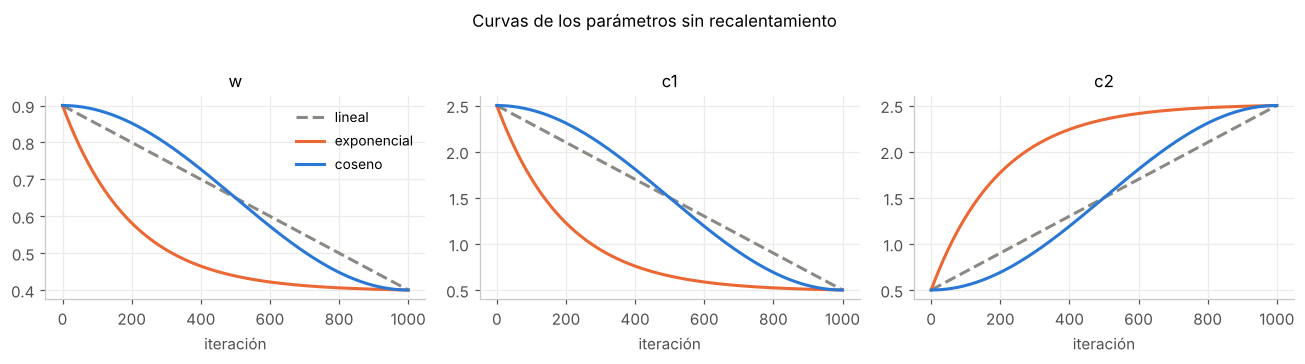

In [6]:
def parametros(s, cfg):
    s = min(max(s, 0.0), 1.0)
    curva = cfg.get("curva", "coseno")
    if curva == "coseno":
        g = 0.5 * (1 + math.cos(math.pi * s))
    elif curva == "exponencial":
        g = (math.exp(-5 * s) - math.exp(-5)) / (1 - math.exp(-5))
    else:
        g = 1 - s
    w  = cfg["w_fin"]  + (cfg["w_ini"]  - cfg["w_fin"])  * g
    c1 = cfg["c1_fin"] + (cfg["c1_ini"] - cfg["c1_fin"]) * g
    c2 = cfg["c2_fin"] + (cfg["c2_ini"] - cfg["c2_fin"]) * g
    return w, c1, c2

T = CFG["iteraciones"]
t = np.arange(T + 1)
fig, axs = plt.subplots(1, 3, figsize=(12, 3.2), sharex=True)
for ax, nombre, i in zip(axs, ["w", "c1", "c2"], range(3)):
    for curva, col, ls in [("lineal", GRIS, "--"), ("exponencial", NARANJA, "-"), ("coseno", AZUL, "-")]:
        ax.plot(t, [parametros(k / T, dict(CFG, curva=curva))[i] for k in t], color=col, ls=ls, label=curva)
    ax.set_title(nombre); ax.set_xlabel("iteración")
axs[0].legend()
fig.suptitle("Curvas de los parámetros sin recalentamiento", y=1.02, fontsize=11)
plt.tight_layout(); plt.show()

## 5. PSO y medidas de diversidad

En cada iteración se registran `gbest` y tres medidas de diversidad. Todas son la **distancia media de los vectores a su centroide**, dividida entre una escala para que queden entre 0 y ~0.5 y se puedan comparar entre cadenas de distinto tamaño (`D = 3(n−2)` dimensiones):

| Medida | Qué vectores mide | Normalización | Qué significa |
|---|---|---|---|
| Diversidad de posición | posiciones actuales `x_i` | `√D` (diagonal del espacio) | qué tan dispersas están las partículas ahora |
| Diversidad de velocidad | velocidades `v_i` | `vmax·√D` | qué tan distintos son sus movimientos (si es ~0, el enjambre está quieto o se mueve en bloque) |
| Diversidad cognitiva | mejores personales `pbest_i` | `√D` | qué tan distintas son las memorias de las partículas; mide cuántas regiones prometedoras se recuerdan |

Como referencia, partículas repartidas al azar en el cubo dan una diversidad de posición (y cognitiva) ≈ 0.29, y velocidades al azar en `[−vmax, vmax]` dan una diversidad de velocidad ≈ 0.58. Esos son los valores de la iteración 0.

Otros detalles: `pbest` se actualiza también con **empates** (`≤`), para que las partículas puedan desplazarse por las mesetas; las posiciones que salen de `[0, 1]` se recortan y su velocidad rebota a la mitad.

In [7]:
def diversidad(M, escala):
    return float(np.linalg.norm(M - M.mean(axis=0), axis=1).mean() / escala)


def pso_una_corrida(seq, cfg, semilla):
    rng = np.random.default_rng(semilla)
    n = len(seq)
    es_h = np.array([c == "H" for c in seq])
    D = 3 * (n - 2)
    P, T, vmax = cfg["particulas"], cfg["iteraciones"], cfg["vmax"]
    raizD = math.sqrt(D)

    X = rng.random((P, D))
    V = rng.uniform(-vmax, vmax, (P, D))
    f = evaluar_enjambre(X, es_h, DX, DY, GIRO)
    pbest, pfit = X.copy(), f.copy()
    g = int(np.argmin(pfit))
    gbest, gfit = pbest[g].copy(), pfit[g]

    h = {k: np.empty(T + 1) for k in ["gbest", "div_pos", "div_vel", "div_cog", "w", "c1", "c2"]}
    s, b, sin_mejora, n_recal = 0.0, 0.0, 0, 0
    w, c1, c2 = parametros(s, cfg)

    def registrar(t):
        h["gbest"][t] = gfit
        h["div_pos"][t] = diversidad(X, raizD)
        h["div_vel"][t] = diversidad(V, vmax * raizD)
        h["div_cog"][t] = diversidad(pbest, raizD)
        h["w"][t], h["c1"][t], h["c2"][t] = w, c1, c2

    registrar(0)
    for t in range(1, T + 1):
        w, c1, c2 = parametros(s, cfg)
        r1, r2 = rng.random((P, D)), rng.random((P, D))
        V = w * V + c1 * r1 * (pbest - X) + c2 * r2 * (gbest - X)
        np.clip(V, -vmax, vmax, out=V)
        X = X + V
        fuera = (X < 0) | (X > 1)
        V[fuera] *= -0.5
        np.clip(X, 0.0, 1.0, out=X)

        f = evaluar_enjambre(X, es_h, DX, DY, GIRO)
        mejora = f <= pfit
        pbest[mejora], pfit[mejora] = X[mejora], f[mejora]
        g = int(np.argmin(pfit))
        if pfit[g] < gfit:
            gbest, gfit = pbest[g].copy(), pfit[g]
            sin_mejora = 0
        else:
            sin_mejora += 1

        # fase = avance del reloj − retroceso por recalentamiento (que se desvanece)
        b *= cfg["decaimiento"]
        if sin_mejora >= cfg["paciencia"]:
            b = min(b + cfg["impulso"], t / T)
            sin_mejora, n_recal = 0, n_recal + 1
        s = t / T - b
        registrar(t)

    h["gbest_x"], h["recalentamientos"] = gbest, n_recal
    return h


def correr_experimento(seq, cfg, n_corridas, semilla_base, etiqueta=""):
    hs, t0 = [], time.time()
    for r in range(n_corridas):
        hs.append(pso_una_corrida(seq, cfg, semilla_base + r))
    claves = ["gbest", "div_pos", "div_vel", "div_cog", "w", "c1", "c2"]
    res = {k: np.vstack([h[k] for h in hs]) for k in claves}   # matriz (corridas × iteraciones)
    res["gbest_x"] = [h["gbest_x"] for h in hs]
    res["recalentamientos"] = np.array([h["recalentamientos"] for h in hs])
    res["tiempo"] = time.time() - t0
    if etiqueta:
        print(f"{etiqueta:<9} {n_corridas} corridas en {res['tiempo']:.1f} s")
    return res

# compilar numba una vez (no cuenta en los tiempos)
_ = pso_una_corrida(CADENAS["S1-20"][0], dict(CFG, iteraciones=2), 0)

## 6. Ejecución: 30 corridas por cadena

In [8]:
RES = {}
for k in CADENAS_A_CORRER:
    seq, _ = CADENAS[k]
    RES[k] = correr_experimento(seq, CFG, N_CORRIDAS, SEMILLA_BASE, etiqueta=k)

S1-20     30 corridas en 22.9 s


S2-24     30 corridas en 29.1 s


S4-36     30 corridas en 42.5 s


S5-48     30 corridas en 52.7 s


S8-64     30 corridas en 61.9 s


## 7. Resultados de `gbest`

`gbest` final de cada corrida. **Éxito** = la corrida alcanzó la energía mínima conocida. **Iteración de la última mejora** = cuándo encontró su resultado final (indica si siguió mejorando hasta el final o se estancó antes).

In [9]:
def iter_ultima_mejora(G):
    # primera iteración en la que cada corrida alcanzó su valor final
    return np.array([int(np.argmax(g == g[-1])) for g in G])

print(f"{'Cadena':<9}{'E conocida':>11}{'Mejor':>7}{'Peor':>7}{'Mediana':>9}{'Media ± DE':>16}"
      f"{'Éxito':>9}{'Error rel.':>12}{'Últ. mejora (media)':>21}{'Recal./corrida':>16}")
print("-" * 117)
for k in CADENAS_A_CORRER:
    G = RES[k]["gbest"]; fin = G[:, -1]; e = CADENAS[k][1]
    exito = f"{(fin == e).sum()}/{len(fin)}" if e is not None else "—"
    err = f"{100 * (fin.mean() - e) / abs(e):.1f} %" if e is not None else "—"
    ult = iter_ultima_mejora(G)
    print(f"{k:<9}{str(e):>11}{fin.min():>7.0f}{fin.max():>7.0f}{np.median(fin):>9.1f}"
          f"{fin.mean():>9.2f} ± {fin.std(ddof=1):<4.2f}{exito:>9}{err:>12}"
          f"{ult.mean():>14.0f} ± {ult.std(ddof=1):<4.0f}{RES[k]['recalentamientos'].mean():>14.1f}")

Cadena    E conocida  Mejor   Peor  Mediana      Media ± DE    Éxito  Error rel.  Últ. mejora (media)  Recal./corrida
---------------------------------------------------------------------------------------------------------------------
S1-20             -9     -9     -8     -9.0    -8.67 ± 0.48    20/30       3.7 %            59 ± 49            18.7
S2-24             -9     -9     -7     -8.0    -8.17 ± 0.59     8/30       9.3 %           131 ± 181           18.6
S4-36            -14    -14    -11    -12.0   -12.33 ± 0.96     4/30      11.9 %           292 ± 199           17.7
S5-48            -23    -21    -15    -19.0   -18.73 ± 1.39     0/30      18.6 %           558 ± 192           16.7
S8-64            -42    -33    -24    -30.0   -29.73 ± 2.33     0/30      29.2 %           668 ± 211           16.0


### Gráfica de convergencia

Línea = media de `gbest` en las 30 corridas; banda = ± 1 desviación estándar; línea punteada = energía mínima conocida.

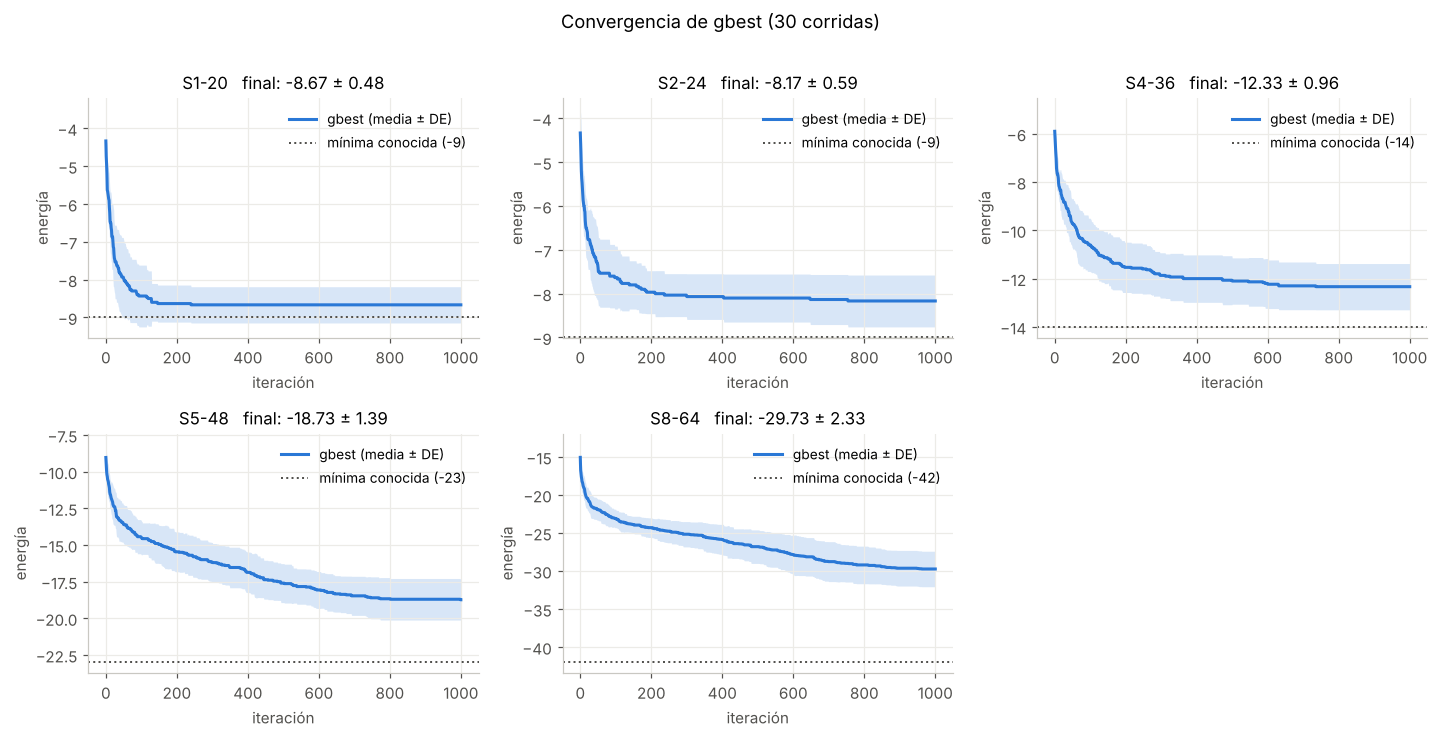

In [10]:
def banda(ax, M, color, label=None):
    t = np.arange(M.shape[1]); mu, sd = M.mean(0), M.std(0, ddof=1)
    ax.fill_between(t, mu - sd, mu + sd, color=color, alpha=0.18, lw=0)
    ax.plot(t, mu, color=color, label=label)

nc = len(CADENAS_A_CORRER)
cols = min(nc, 3); filas = math.ceil(nc / cols)
fig, axs = plt.subplots(filas, cols, figsize=(4.4 * cols, 3.3 * filas), squeeze=False)
for ax, k in zip(axs.flat, CADENAS_A_CORRER):
    banda(ax, RES[k]["gbest"], AZUL, "gbest (media ± DE)")
    e = CADENAS[k][1]
    if e is not None:
        ax.axhline(e, color=TINTA2, ls=":", lw=1.3, label=f"mínima conocida ({e})")
    fin = RES[k]["gbest"][:, -1]
    ax.set_title(f"{k}   final: {fin.mean():.2f} ± {fin.std(ddof=1):.2f}")
    ax.set_xlabel("iteración"); ax.set_ylabel("energía")
    ax.legend(loc="upper right")
for ax in axs.flat[nc:]:
    ax.axis("off")
fig.suptitle("Convergencia de gbest (30 corridas)", fontsize=12, y=1.01)
plt.tight_layout(); plt.show()

## 8. Diversidad

Cada fila es una medida de diversidad y cada columna una cadena. Línea = media; banda = ± 1 desviación estándar entre corridas. La última fila muestra los parámetros realmente usados: por los recalentamientos, `w`, `c1` y `c2` medios se separan de la curva coseno ideal (sección 4), y la banda indica cuánto variaron entre corridas.

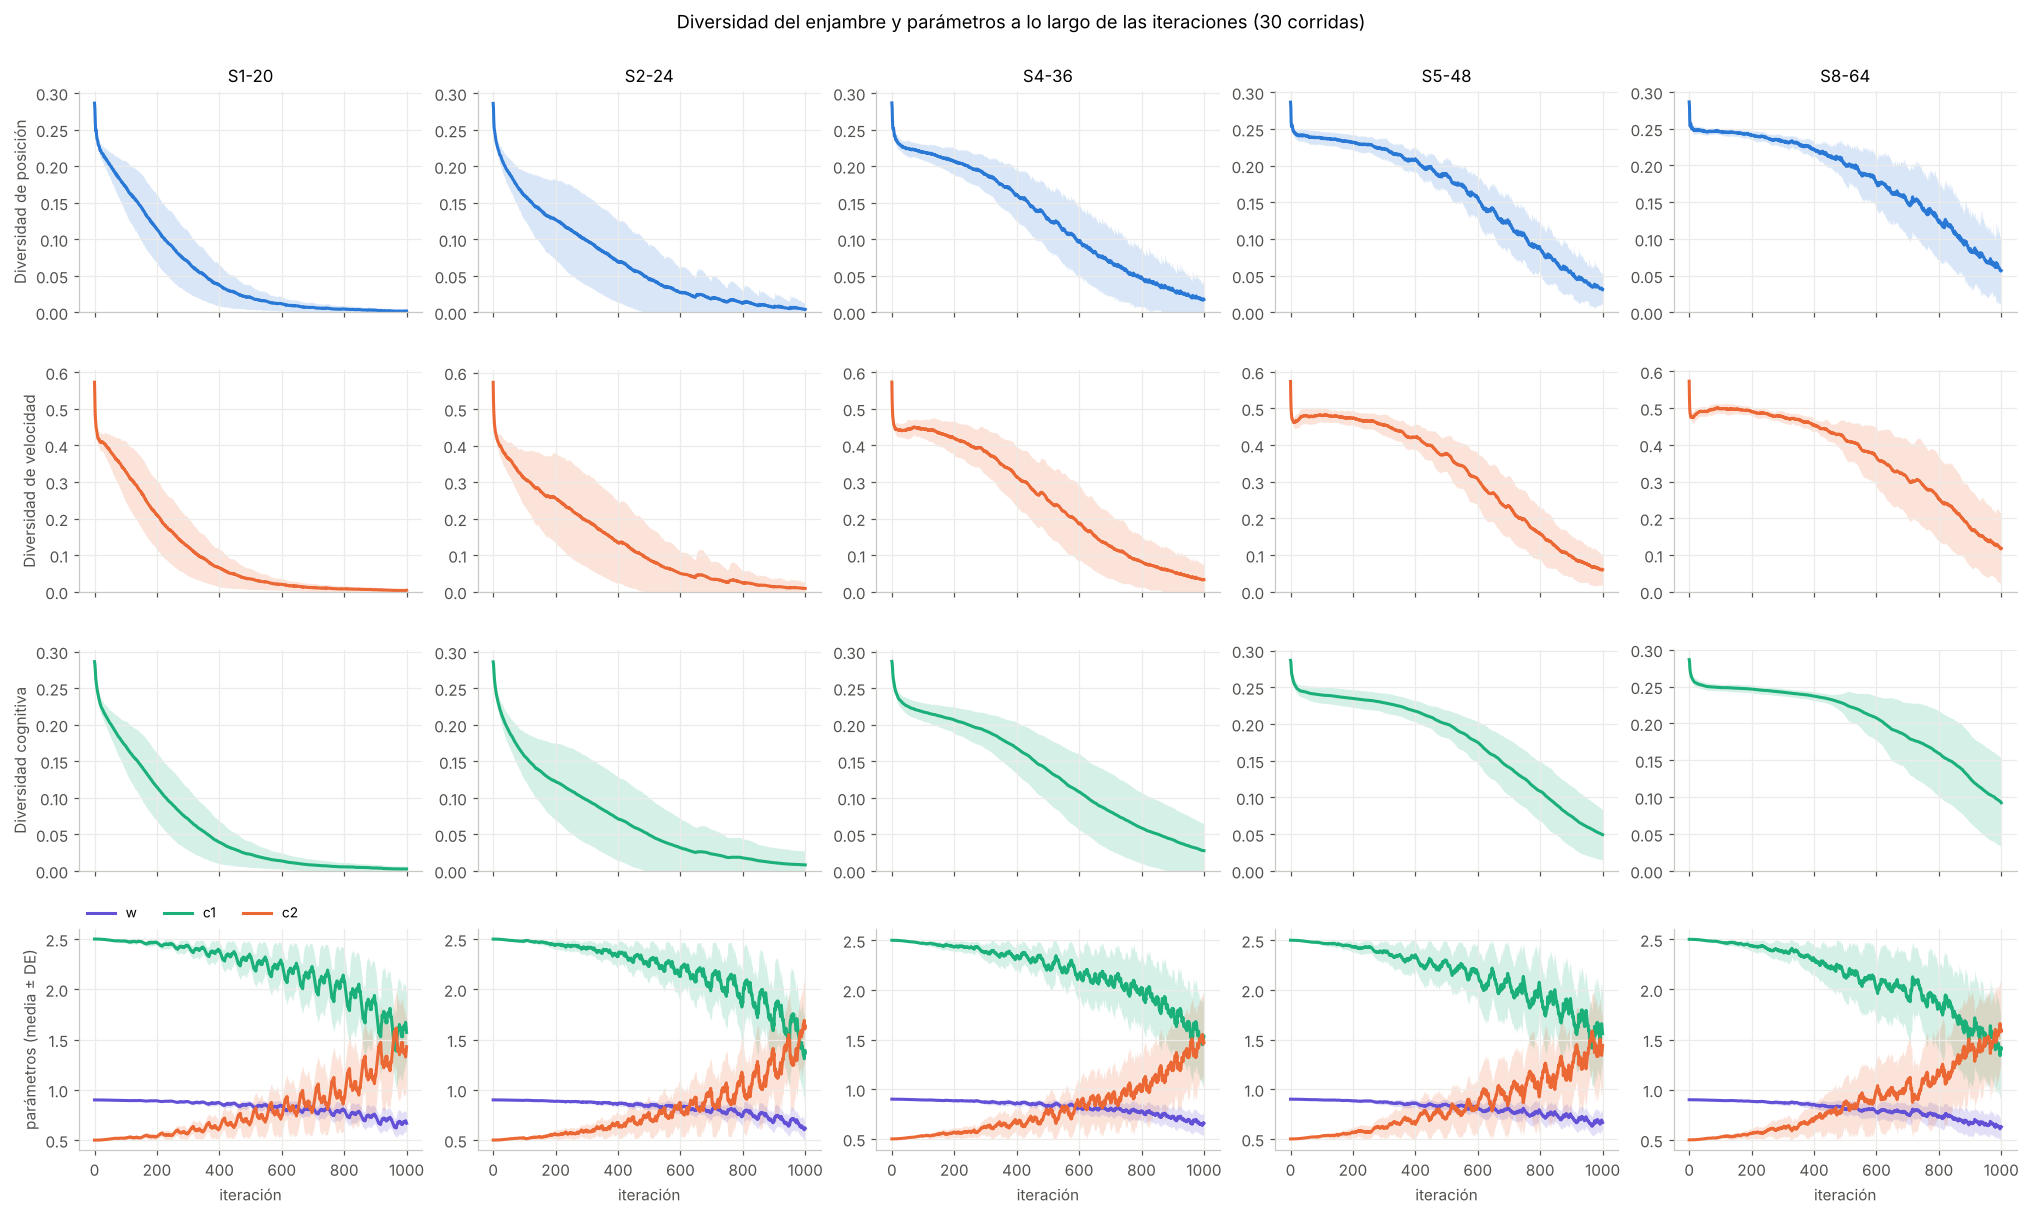

In [11]:
METRICAS = [("div_pos", "Diversidad de posición", AZUL),
            ("div_vel", "Diversidad de velocidad", NARANJA),
            ("div_cog", "Diversidad cognitiva", AQUA)]

fig, axs = plt.subplots(4, nc, figsize=(3.7 * nc, 11), squeeze=False, sharex=True)
for j, k in enumerate(CADENAS_A_CORRER):
    for i, (m, nombre, col) in enumerate(METRICAS):
        ax = axs[i, j]
        banda(ax, RES[k][m], col)
        ax.set_ylim(bottom=0)
        if j == 0: ax.set_ylabel(nombre)
        if i == 0: ax.set_title(k)
    ax = axs[3, j]
    banda(ax, RES[k]["w"], VIOLETA, "w")
    banda(ax, RES[k]["c1"], AQUA, "c1")
    banda(ax, RES[k]["c2"], NARANJA, "c2")
    ax.set_xlabel("iteración")
    if j == 0:
        ax.set_ylabel("parámetros (media ± DE)")
        ax.legend(loc="lower left", ncol=3, bbox_to_anchor=(0.0, 1.0), borderaxespad=0.2)
fig.suptitle("Diversidad del enjambre y parámetros a lo largo de las iteraciones (30 corridas)", fontsize=12, y=1.0)
plt.tight_layout(); plt.show()

### Las tres diversidades juntas, por cadena

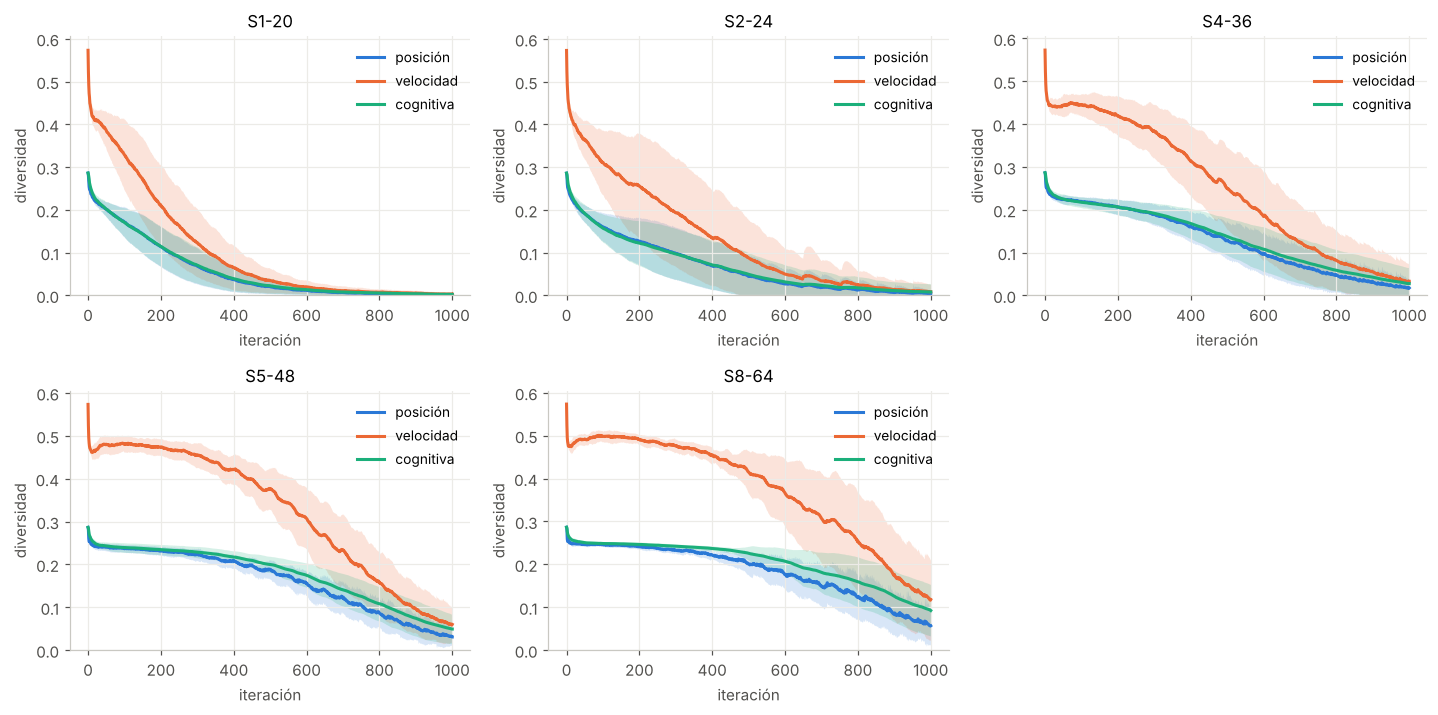

In [12]:
fig, axs = plt.subplots(filas, cols, figsize=(4.4 * cols, 3.3 * filas), squeeze=False)
for ax, k in zip(axs.flat, CADENAS_A_CORRER):
    for m, nombre, col in METRICAS:
        banda(ax, RES[k][m], col, nombre.replace("Diversidad de ", "").replace("Diversidad ", ""))
    ax.set_title(k); ax.set_xlabel("iteración"); ax.set_ylabel("diversidad"); ax.set_ylim(bottom=0)
    ax.legend(loc="upper right")
for ax in axs.flat[nc:]:
    ax.axis("off")
plt.tight_layout(); plt.show()

### Tabla de diversidad en momentos clave (media ± DE)

In [13]:
momentos = [0, int(0.1 * T), int(0.25 * T), int(0.5 * T), int(0.75 * T), T]
for m, nombre, _ in METRICAS:
    print(f"\n{nombre}")
    print(f"{'Cadena':<9}" + "".join(f"{'it ' + str(t):>16}" for t in momentos))
    for k in CADENAS_A_CORRER:
        M = RES[k][m]
        print(f"{k:<9}" + "".join(f"{M[:, t].mean():>9.3f} ± {M[:, t].std(ddof=1):.3f}" for t in momentos))


Diversidad de posición
Cadena               it 0          it 100          it 250          it 500          it 750         it 1000
S1-20        0.286 ± 0.002    0.172 ± 0.035    0.089 ± 0.047    0.021 ± 0.016    0.006 ± 0.006    0.002 ± 0.003
S2-24        0.286 ± 0.002    0.160 ± 0.034    0.113 ± 0.062    0.045 ± 0.045    0.014 ± 0.020    0.004 ± 0.008
S4-36        0.287 ± 0.001    0.220 ± 0.011    0.198 ± 0.022    0.129 ± 0.044    0.058 ± 0.043    0.018 ± 0.023
S5-48        0.287 ± 0.001    0.237 ± 0.009    0.228 ± 0.010    0.189 ± 0.023    0.105 ± 0.035    0.031 ± 0.020
S8-64        0.287 ± 0.001    0.246 ± 0.004    0.237 ± 0.006    0.201 ± 0.026    0.142 ± 0.050    0.057 ± 0.044

Diversidad de velocidad
Cadena               it 0          it 100          it 250          it 500          it 750         it 1000
S1-20        0.573 ± 0.003    0.329 ± 0.083    0.163 ± 0.091    0.035 ± 0.029    0.009 ± 0.010    0.004 ± 0.005
S2-24        0.573 ± 0.003    0.311 ± 0.076    0.225 ± 0.132    0.0

### Mejor plegamiento encontrado por cadena

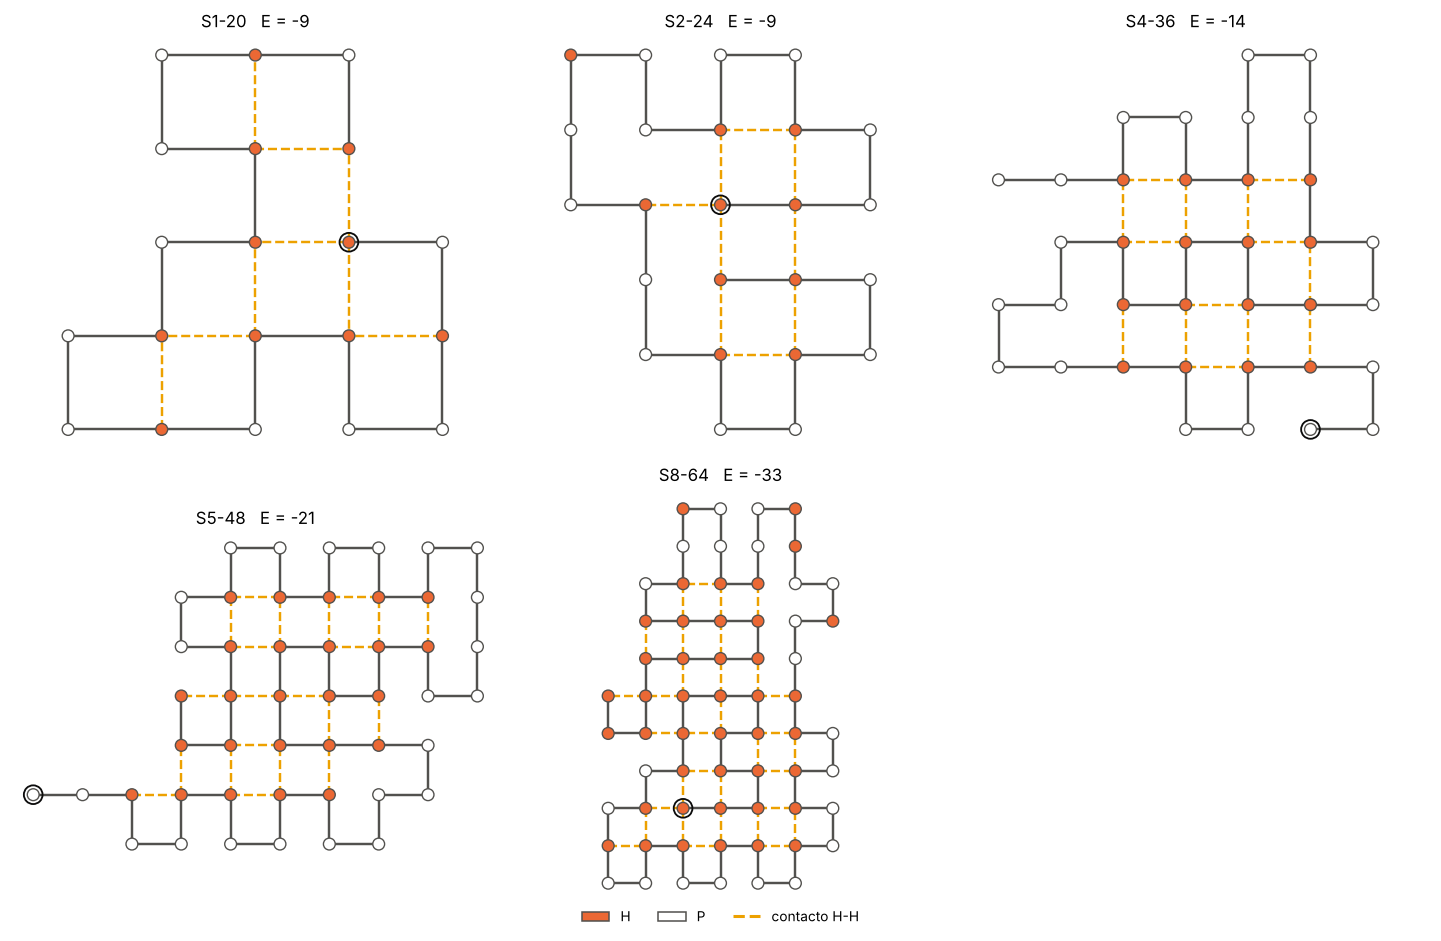

In [14]:
def dibujar(ax, seq, x, titulo):
    xy, e, c = forma(x, seq)
    idx = {tuple(p): i for i, p in enumerate(xy)}
    for i, p in enumerate(xy):
        if seq[i] != "H": continue
        for dx, dy in [(1, 0), (0, 1), (-1, 0), (0, -1)]:
            j = idx.get((p[0] + dx, p[1] + dy))
            if j is not None and j > i + 1 and seq[j] == "H":
                ax.plot([p[0], xy[j][0]], [p[1], xy[j][1]], color="#eda100", ls="--", lw=1.6, zorder=1)
    ax.plot(xy[:, 0], xy[:, 1], color=TINTA2, lw=1.6, zorder=2)
    colores = [NARANJA if seq[i] == "H" else "#ffffff" for i in range(c)]
    ax.scatter(xy[:, 0], xy[:, 1], s=60, c=colores, edgecolors=TINTA2, linewidths=0.9, zorder=3)
    ax.scatter([xy[0, 0]], [xy[0, 1]], s=150, facecolors="none", edgecolors=TINTA, linewidths=1.2, zorder=4)
    ax.set_title(f"{titulo}   E = {e}"); ax.set_aspect("equal"); ax.axis("off")

fig, axs = plt.subplots(filas, cols, figsize=(4.4 * cols, 4.2 * filas), squeeze=False)
for ax, k in zip(axs.flat, CADENAS_A_CORRER):
    seq = CADENAS[k][0]
    b = int(np.argmin(RES[k]["gbest"][:, -1]))
    dibujar(ax, seq, RES[k]["gbest_x"][b], k)
for ax in axs.flat[nc:]:
    ax.axis("off")
fig.legend(handles=[Patch(facecolor=NARANJA, edgecolor=TINTA2, label="H"),
                    Patch(facecolor="#ffffff", edgecolor=TINTA2, label="P"),
                    plt.Line2D([], [], color="#eda100", ls="--", label="contacto H-H")],
           loc="lower center", ncol=3, bbox_to_anchor=(0.5, -0.02))
plt.tight_layout(); plt.show()

## 9. ¿Fue buena la elección de la estrategia? Comparación experimental

Se corre el mismo PSO (mismas semillas, mismas partículas e iteraciones) con cuatro estrategias, 30 corridas cada una:

1. **lineal**: la referencia clásica.
2. **exponencial**: cae rápido al inicio.
3. **coseno**: la curva elegida, sin recalentamiento.
4. **coseno + recalentamiento**: la estrategia completa usada arriba.

Para saber si las diferencias son reales y no suerte, se aplica la prueba de Mann-Whitney (unilateral: ¿la estrategia elegida da energías más bajas que la otra?). Un valor p < 0.05 indica una diferencia estadísticamente significativa.

In [15]:
ESTRATEGIAS = {
    "lineal":              dict(curva="lineal",      paciencia=10**9),
    "exponencial":         dict(curva="exponencial", paciencia=10**9),
    "coseno":              dict(curva="coseno",      paciencia=10**9),
    "coseno + recalent.":  dict(curva="coseno"),
}
COMP = {}
if COMPARAR_ESTRATEGIAS:
    for k in CADENAS_COMPARACION:
        seq = CADENAS[k][0]
        for nombre, extra in ESTRATEGIAS.items():
            if nombre == "coseno + recalent." and k in RES:
                COMP[(k, nombre)] = RES[k]["gbest"]          # ya corrida con la misma configuración
            else:
                COMP[(k, nombre)] = correr_experimento(seq, dict(CFG, **extra), N_CORRIDAS, SEMILLA_BASE)["gbest"]
        print(f"{k} listo")

S1-20 listo


S4-36 listo



S1-20  (mínima conocida -9)
Estrategia                  Media ± DE  Mejor   Éxito   p vs. elegida
lineal                    -8.33 ± 0.76     -9   14/30          0.0384
exponencial               -7.63 ± 1.19     -9    9/30          0.0002
coseno                    -8.63 ± 0.49     -9   19/30          0.3976
coseno + recalent.        -8.67 ± 0.48     -9   20/30               —

S4-36  (mínima conocida -14)
Estrategia                  Media ± DE  Mejor   Éxito   p vs. elegida
lineal                   -11.50 ± 1.33    -14    3/30          0.0037
exponencial              -10.80 ± 1.47    -14    1/30          0.0000
coseno                   -11.80 ± 1.13    -14    2/30          0.0354
coseno + recalent.       -12.33 ± 0.96    -14    4/30               —


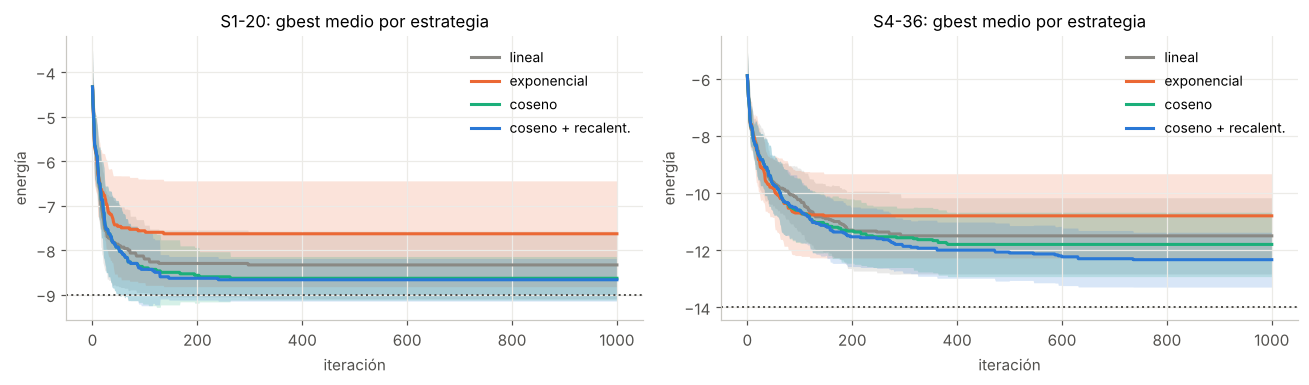

In [16]:
if COMPARAR_ESTRATEGIAS:
    ref = "coseno + recalent."
    for k in CADENAS_COMPARACION:
        e = CADENAS[k][1]
        print(f"\n{k}  (mínima conocida {e})")
        print(f"{'Estrategia':<22}{'Media ± DE':>16}{'Mejor':>7}{'Éxito':>8}{'p vs. elegida':>16}")
        for nombre in ESTRATEGIAS:
            fin = COMP[(k, nombre)][:, -1]
            p = "—"
            if nombre != ref and mannwhitneyu is not None:
                p = f"{mannwhitneyu(COMP[(k, ref)][:, -1], fin, alternative='less').pvalue:.4f}"
            print(f"{nombre:<22}{fin.mean():>9.2f} ± {fin.std(ddof=1):<4.2f}{fin.min():>7.0f}"
                  f"{(fin == e).sum():>5}/{len(fin):<2}{p:>16}")

    fig, axs = plt.subplots(1, len(CADENAS_COMPARACION), figsize=(6 * len(CADENAS_COMPARACION), 3.6), squeeze=False)
    colores = {"lineal": GRIS, "exponencial": NARANJA, "coseno": AQUA, "coseno + recalent.": AZUL}
    for ax, k in zip(axs.flat, CADENAS_COMPARACION):
        for nombre in ESTRATEGIAS:
            banda(ax, COMP[(k, nombre)], colores[nombre], nombre)
        ax.axhline(CADENAS[k][1], color=TINTA2, ls=":", lw=1.3)
        ax.set_title(f"{k}: gbest medio por estrategia"); ax.set_xlabel("iteración"); ax.set_ylabel("energía")
        ax.legend(loc="upper right")
    plt.tight_layout(); plt.show()

## 10. Conclusiones

Con la configuración por defecto (80 partículas, 1000 iteraciones, 30 corridas por cadena):

**Calidad de `gbest`.** El PSO encuentra la energía mínima conocida en las cadenas cortas (S1-20 en 20 de 30 corridas, S2-24 en 8 de 30, S4-36 en 4 de 30), pero el error relativo crece con la longitud: alrededor de 19 % en S5-48 (mejor −21 de −23) y 29 % en S8-64 (mejor −33 de −42). Es el comportamiento esperado de un PSO "puro" en este problema; los métodos que alcanzan los récords en cadenas largas combinan la búsqueda global con búsqueda local (por ejemplo, *pull moves*).

**Diversidad.** En las cadenas cortas las tres medidas caen casi a cero antes de la iteración 500: el enjambre colapsa sobre una sola forma y, como `gbest` ya no cambia, el resto de las iteraciones aporta poco. En las cadenas largas las tres siguen la forma de la curva coseno (se mantienen altas al inicio y caen en la segunda mitad), y la iteración de la última mejora se acerca al final de la corrida: el presupuesto de iteraciones se queda corto y el enjambre seguiría mejorando con más tiempo. En las cadenas largas, la diversidad cognitiva es la última en caer, lo que indica que las memorias de las partículas conservan regiones distintas aun cuando las posiciones actuales ya se agruparon.

**Estrategia de parámetros.** La curva coseno con recalentamiento obtiene la mejor media y la mayor tasa de éxito en las dos cadenas comparadas. La diferencia contra la curva lineal y contra la exponencial es estadísticamente significativa (p < 0.05) en ambas cadenas. Contra el coseno sin recalentamiento, la ventaja es significativa en S4-36 pero no en S1-20, que es tan corta que casi cualquier estrategia razonable la resuelve. La curva exponencial es la peor: apagar la exploración pronto deja al enjambre atrapado en las mesetas del paisaje HP.

**Siguientes pasos naturales.** (1) Aumentar las iteraciones para las cadenas de 48 o más, ya que todavía estaban mejorando; (2) agregar búsqueda local sobre `gbest` (*pull moves*); (3) probar una topología en anillo (`lbest`), que tiende a conservar más diversidad que la topología global.